# 132STA - Direct stiffness method for a trusses

Apply the matrix approach to the direct stiffness method on a problem shown during the lecture.

### 0. Preparation

Run the compact **Setup** cell once, then run the imports below. Expand the setup code only if you want to inspect it. In Colab, it loads the teaching functions at commit `cf36c7d`; locally, it uses your checkout.

In [55]:
# @title Setup: load teaching functions (run first) { display-mode: "form" }
# Locate the teaching package (Colab or local Jupyter)
from pathlib import Path
import subprocess
import sys

revision = "cf36c7d744b5f80b14384b3a6bd9df684f98e81d"  # Original Lecture 05 truss functions.
repo = Path.cwd()
if not (repo / "sta132").is_dir():
    if (repo.parent / "sta132").is_dir():
        repo = repo.parent
    else:
        repo = Path(f"/content/132sta-python-05-{revision[:7]}")
        if not (repo / ".git").is_dir():
            subprocess.run(
                ["git", "clone", "--quiet", "--no-checkout",
                 "https://github.com/MartinDoskar/132sta-python.git", str(repo)],
                check=True,
            )
            subprocess.run(
                ["git", "checkout", "--quiet", "--detach", revision],
                cwd=repo, check=True,
            )
        actual_revision = subprocess.check_output(
            ["git", "rev-parse", "HEAD"], cwd=repo, text=True,
        ).strip()
        if actual_revision != revision:
            raise RuntimeError("The cached teaching package is not at the Lecture 05 commit.")
sys.path.insert(0, str(repo))
print("Using teaching functions from:", repo)


Using teaching functions from: /content/132sta-python-05-cf36c7d


In [56]:
import numpy as np
import matplotlib.pyplot as plt
from sta132.truss import stiffness_matrix_truss, axial_force_truss
from sta132.plotting import plot_truss
np.set_printoptions(precision=4, suppress=True)

### 1. Define the problem/structure

The structure is defined with coordinates of the joints and elements defined by their endpoints.
Plus, define the material and cross-sectional characteristics.

In [57]:
# Node coordinates [x, z] in metres
xz = np.array([[0, 2.7],     # Node 1
               [0, 0],       # Node 2
               [3.6, 2.7]])  # Node 3

# Member endpoints, using zero-based Python node indices
bars = np.array([[0, 1],   # Member 1--2
                 [1, 2]])  # Member 2--3

# Required axial rigidity
EA = 500e3         # kN = 500 MN

# The functions require E and A separately.
# Choose a reference E and obtain A so that E*A = EA.
E = 200e6         # kN/m²
A = EA / E        # m²

print("EA =", E * A, "kN")

EA = 500000.0 kN


### 2. Member stiffness relations

Compute stiffness matrices of each truss element in the global coordinate system.

In [58]:
K1, Kloc1, T1 = stiffness_matrix_truss(E, A, xz[0], xz[1])
K2, Kloc2, T2 = stiffness_matrix_truss(E, A, xz[1], xz[2])


print("K1:\n", K1)
print("K2:\n", K2)

K1:
 [[      0.           0.           0.           0.    ]
 [      0.      185185.1852       0.     -185185.1852]
 [      0.           0.           0.           0.    ]
 [      0.     -185185.1852       0.      185185.1852]]
K2:
 [[ 71111.1111  53333.3333 -71111.1111 -53333.3333]
 [ 53333.3333  40000.     -53333.3333 -40000.    ]
 [-71111.1111 -53333.3333  71111.1111  53333.3333]
 [-53333.3333 -40000.      53333.3333  40000.    ]]


### 3. Compatibility, equilibrium, and code numbers

Construct the global stiffness matrix using manually provided code numbers.
Keep the one-based code numbers separate from the zero-based Python indices.

In [59]:
K = np.zeros((6, 6))

code_numbers1 = np.array([1, 2, 3, 4])  # Member 1--2
code_numbers2 = np.array([3, 4, 5, 6])  # Member 2--3

# Lecture code numbers start at 1; Python array indices start at 0.
indices1 = code_numbers1 - 1
indices2 = code_numbers2 - 1

K[np.ix_(indices1, indices1)] += K1
K[np.ix_(indices2, indices2)] += K2


print("K [10^3 kN/m]:\n", K / 1e3)

K [10^3 kN/m]:
 [[   0.        0.        0.        0.        0.        0.    ]
 [   0.      185.1852    0.     -185.1852    0.        0.    ]
 [   0.        0.       71.1111   53.3333  -71.1111  -53.3333]
 [   0.     -185.1852   53.3333  225.1852  -53.3333  -40.    ]
 [   0.        0.      -71.1111  -53.3333   71.1111   53.3333]
 [   0.        0.      -53.3333  -40.       53.3333   40.    ]]


### 4. Supports and applied load

Solve the system by extracting a subsystem pertinent to free DOFs.

In [60]:
p = np.zeros(6)    # Applied nodal loads [kN]
p[2] = 5.0        # Horizontal load at node 2 (code number 3)

d = np.zeros(6)    # Nodal displacements [m]

free_code_numbers = np.array([3])
fixed_code_numbers = np.array([1, 2, 4, 5, 6])

# Lecture code numbers start at 1; Python array indices start at 0.
free_indices = free_code_numbers - 1
fixed_indices = fixed_code_numbers - 1

Kuu = K[np.ix_(free_indices, free_indices)]

# Full displacement vector: [u1, w1, u2, w2, u3, w3]
d = np.zeros(6)

# Insert the unknown displacement into its global position
d[free_indices] = np.linalg.solve(Kuu, p[free_indices])

print("d.shape:", d.shape)
print("Displacements [mm]:", 1000 * d)

d.shape: (6,)
Displacements [mm]: [0.     0.     0.0703 0.     0.     0.    ]


### 5. Support reactions

Obtain reactions by back-substitution into the global (unpartitioned) system.

In [61]:
r = K @ d - p
print("Reaction vector [kN]:", r)
print("Support reactions [kN]:", r[fixed_indices])
print("Residual at free DOFs [kN]:", r[free_indices])

Reaction vector [kN]: [ 0.    0.    0.    3.75 -5.   -3.75]
Support reactions [kN]: [ 0.    0.    3.75 -5.   -3.75]
Residual at free DOFs [kN]: [0.]


### 6. Member axial forces

Use solution to compute internal forces.

In [62]:
N1 = axial_force_truss(E, A, xz[0], xz[1], d[indices1])
N2 = axial_force_truss(E, A, xz[1], xz[2], d[indices2])

N = np.array([N1, N2])
print("Member forces [kN]:", N)

Member forces [kN]: [ 0.   -6.25]


### 7. Plot the solution

Need scaling of the displacements

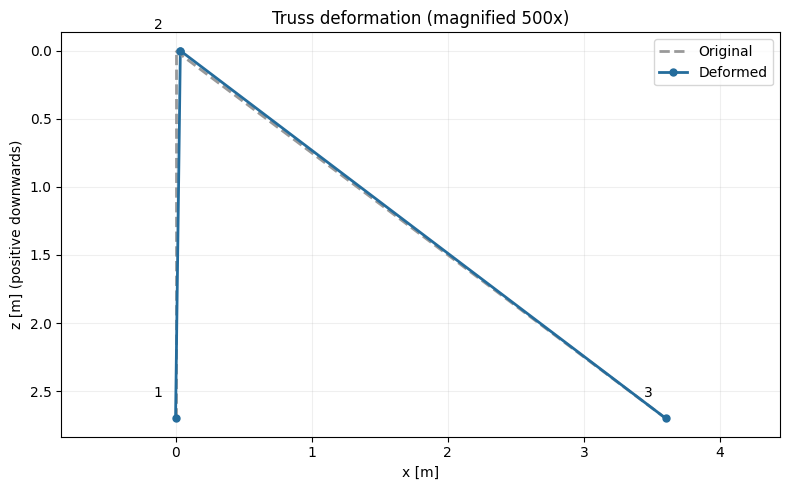

In [63]:
fig, ax = plot_truss(xz, bars, d, scale=500)
plt.show()